# Multiclass Classification Logistic Regression
- Multiclass classification in logistic regression extends the binary classification approach to scenarios where you have more than two classes. In the case of logistic regression, this is typically achieved using a technique called "One-vs-Rest" (OvR) or "One-vs-All."

- Let's explain how multiclass logistic regression works and then apply it to the Iris dataset as requested:

- Multiclass Logistic Regression (One-vs-Rest):

- **Data Preparation:** You start with a dataset where each data point belongs to one of multiple classes. In the Iris dataset, for instance, there are three classes of iris plants (setosa, versicolor, and virginica).

- **One-vs-Rest (OvR) Strategy:** To perform multiclass classification using logistic regression, you create a separate binary logistic regression model for each class. In the OvR strategy:

- For the first class (e.g., setosa), you label the data points of that class as positive (1) and the data points of all other classes as negative (0).
- For the second class (e.g., versicolor), you label its data points as positive and the data points of all other classes as negative.
- For the third class (e.g., virginica), you label its data points as positive and the data points of all other classes as negative.
- Essentially, you're transforming the multiclass problem into multiple binary classification problems.

- **Training:** You train each binary logistic regression model separately. For each model, you optimize the model parameters (weights and bias) using a logistic regression algorithm (e.g., gradient descent) with the corresponding class labels (0 or 1).

- **Prediction:** To make a prediction for a new data point, you apply all the binary models to it. Each model will output a probability score between 0 and 1. The class corresponding to the model with the highest probability is the predicted class for the data point.




In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Load the Iris dataset
iris = sns.load_dataset("iris")


In [ ]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
iris.shape

(150, 5)

In [ ]:
iris["species"].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [ ]:
# separating features and target variable
X = iris.iloc[:,0:4]
y = iris.iloc[:,4]

In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Create a logistic regression model (OvR strategy is the default for multi-class)
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 1.00


In [ ]:
# making prediction
model.predict([[7,10,15,7]])

array(['virginica'], dtype=object)

In [ ]:
iris["species"].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

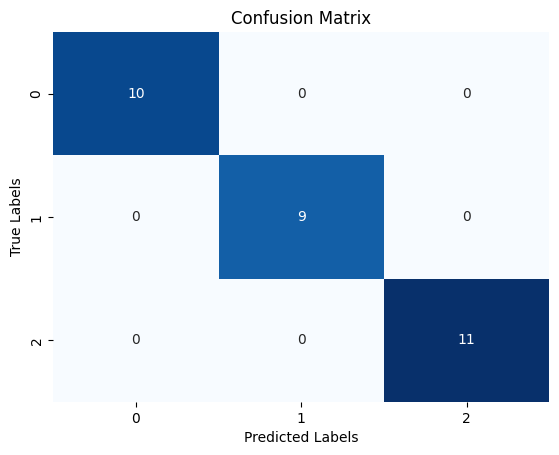

In [ ]:
# confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()